# Chapter 6 — Reproducing the experiments

This chapter shows how the paper's Table 1 was re-measured, what came out, and how far it agrees with the publication. Three kinds of numbers are kept strictly apart:

* **published** — transcribed from the paper (`experiments/paper_table1.json`);
* **reproduced** — measured in this project with the method of Chapters 3–5;
* **additional** — analyses the paper does not contain (marked as such).

## 6.1 Data

| | Paper | This reproduction |
|---|---|---|
| MS COCO labels | 80 categories | the same 80 (`data/coco_labels.json`) |
| COCO ground truth | manual search by the authors (file not available) | re-curated: WordNet synset → WikiData `P8814` → `owl:sameAs`, plus 23 manual corrections checked against live labels and descriptions (`data/coco_manual_ground_truth.json`) |
| Visual Genome ground truth | synset → WikiData `P8814` → DBpedia/YAGO `owl:sameAs`; 2,399 synsets in all three graphs | same procedure, **1,965** synsets today (`experiments/build_ground_truth.py`) |
| Evaluated Visual Genome entries | all 2,399 | seeded random sample of **600** (WikiData, YAGO); a nested subset for DBpedia |
| Graphs | live endpoints, 2024 (YAGO 4) | live endpoints, November 2026 (YAGO 4.5) |

Why a sample? One pass over a label needs about 30 SPARQL requests per graph; the public endpoints allow 1–3 requests per second (DBpedia far less: it refused connections for minutes at a time during this work). 600 entries give a 95 % margin of ±4 points, enough for every conclusion drawn below.

## 6.2 Commands

```bash
# environment
python3 -m venv --system-site-packages .venv && .venv/bin/pip install -r research/requirements.txt
.venv/bin/python -c "import nltk; [nltk.download(c) for c in ('wordnet','wordnet31','omw-1.4')]"

# ground truth, experiment, tables, figures
.venv/bin/python research/experiments/build_ground_truth.py
for kg in wikidata dbpedia yago; do
  .venv/bin/python research/experiments/run_mapping_experiment.py --dataset coco --kg $kg
  .venv/bin/python research/experiments/run_mapping_experiment.py --dataset visual_genome --kg $kg --max-entries 600 --seed 0
done
.venv/bin/python research/experiments/summarise_results.py
.venv/bin/python research/experiments/make_reproduction_figures.py
```

The method is deterministic; the only seed is that of the Visual Genome sample. All SPARQL responses are cached (`research/data/cache/`, not in git), so a finished run can be repeated without network. The cells below read the stored measurements.

In [1]:
# Locate the research/ directory and make the real implementation importable.
import sys, json
from pathlib import Path
RESEARCH = Path.cwd().resolve()
while not (RESEARCH / "pel").is_dir():
    RESEARCH = RESEARCH.parent
for path in (RESEARCH, RESEARCH / "experiments"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
FIGURES = RESEARCH / "experiments" / "figures"
RESULTS = RESEARCH / "experiments" / "results"
%matplotlib inline

In [2]:
summary = json.loads((RESULTS / "reproduction" / "summary.json").read_text())
paper = json.loads((RESEARCH / "experiments" / "paper_table1.json").read_text())
KGS = ("wikidata", "dbpedia", "yago")

def show(dataset):
    cells = summary[dataset]
    n = {kg: next(v[kg]["n"] for c, v in cells.items() if not c.startswith("_") and kg in v) for kg in KGS
         if any(kg in v for c, v in cells.items() if not c.startswith("_"))}
    print(f"{dataset}: hit@1 reproduced (published)   entries evaluated: {n}")
    print(f"{'query':8s} {'process':6s} " + " ".join(f"{kg:>16s}" for kg in KGS))
    for condition, per_kg in cells.items():
        if condition.startswith("_"):
            continue
        query, process = condition.split("|")
        row = [f"{per_kg[kg]['hit@1']:.2f} ({paper[dataset][condition][kg][0]:.2f})" if kg in per_kg
               else f"  –  ({paper[dataset][condition][kg][0]:.2f})" for kg in KGS]
        print(f"{query:8s} {process:6s} " + " ".join(f"{cell:>16s}" for cell in row))

show("coco")

coco: hit@1 reproduced (published)   entries evaluated: {'wikidata': 80, 'dbpedia': 80, 'yago': 80}
query    process         wikidata          dbpedia             yago
S        fq          0.04 (0.08)      0.26 (0.19)      0.31 (0.49)
S        fc          0.04 (0.07)      0.29 (0.19)      0.33 (0.51)
S        fc+fd       0.31 (0.07)      0.31 (0.19)      0.11 (0.51)
S_links  fq          0.88 (0.59)      0.21 (0.24)      0.51 (0.71)
S_links  fc          0.64 (0.59)      0.15 (0.24)      0.50 (0.62)
S_links  fc+fd       0.35 (0.59)      0.26 (0.24)      0.11 (0.71)
L        fq          0.39 (0.50)      0.78 (0.68)      0.51 (0.40)
L        fc          0.44 (0.69)      0.82 (0.69)      0.54 (0.53)
L        fc+fd       0.50 (0.69)      0.80 (0.69)      0.11 (0.55)
L_links  fq          0.79 (0.51)      0.79 (0.84)      0.51 (0.64)
L_links  fc          0.75 (0.14)      0.66 (0.45)      0.55 (0.28)
L_links  fc+fd       0.51 (0.51)      0.64 (0.84)      0.11 (0.64)


In [3]:
show("visual_genome")

visual_genome: hit@1 reproduced (published)   entries evaluated: {'wikidata': 600, 'dbpedia': 150, 'yago': 600}
query    process         wikidata          dbpedia             yago
S        fq          0.04 (0.01)      0.25 (0.09)      0.35 (0.37)
S        fc          0.04 (0.04)      0.27 (0.13)      0.38 (0.45)
S        fc+fd       0.28 (0.22)      0.31 (0.14)      0.16 (0.38)
S_links  fq          0.60 (0.09)      0.19 (0.08)      0.53 (0.26)
S_links  fc          0.54 (0.10)      0.14 (0.11)      0.56 (0.27)
S_links  fc+fd       0.32 (0.31)      0.25 (0.22)      0.18 (0.40)
L        fq          0.42 (0.41)      0.63 (0.37)      0.52 (0.36)
L        fc          0.46 (0.45)      0.66 (0.40)      0.56 (0.43)
L        fc+fd       0.41 (0.29)      0.70 (0.51)      0.18 (0.42)
L_links  fq          0.56 (0.08)      0.63 (0.34)      0.52 (0.25)
L_links  fc          0.58 (0.05)      0.65 (0.24)      0.61 (0.19)
L_links  fc+fd       0.42 (0.24)      0.65 (0.44)      0.19 (0.39)


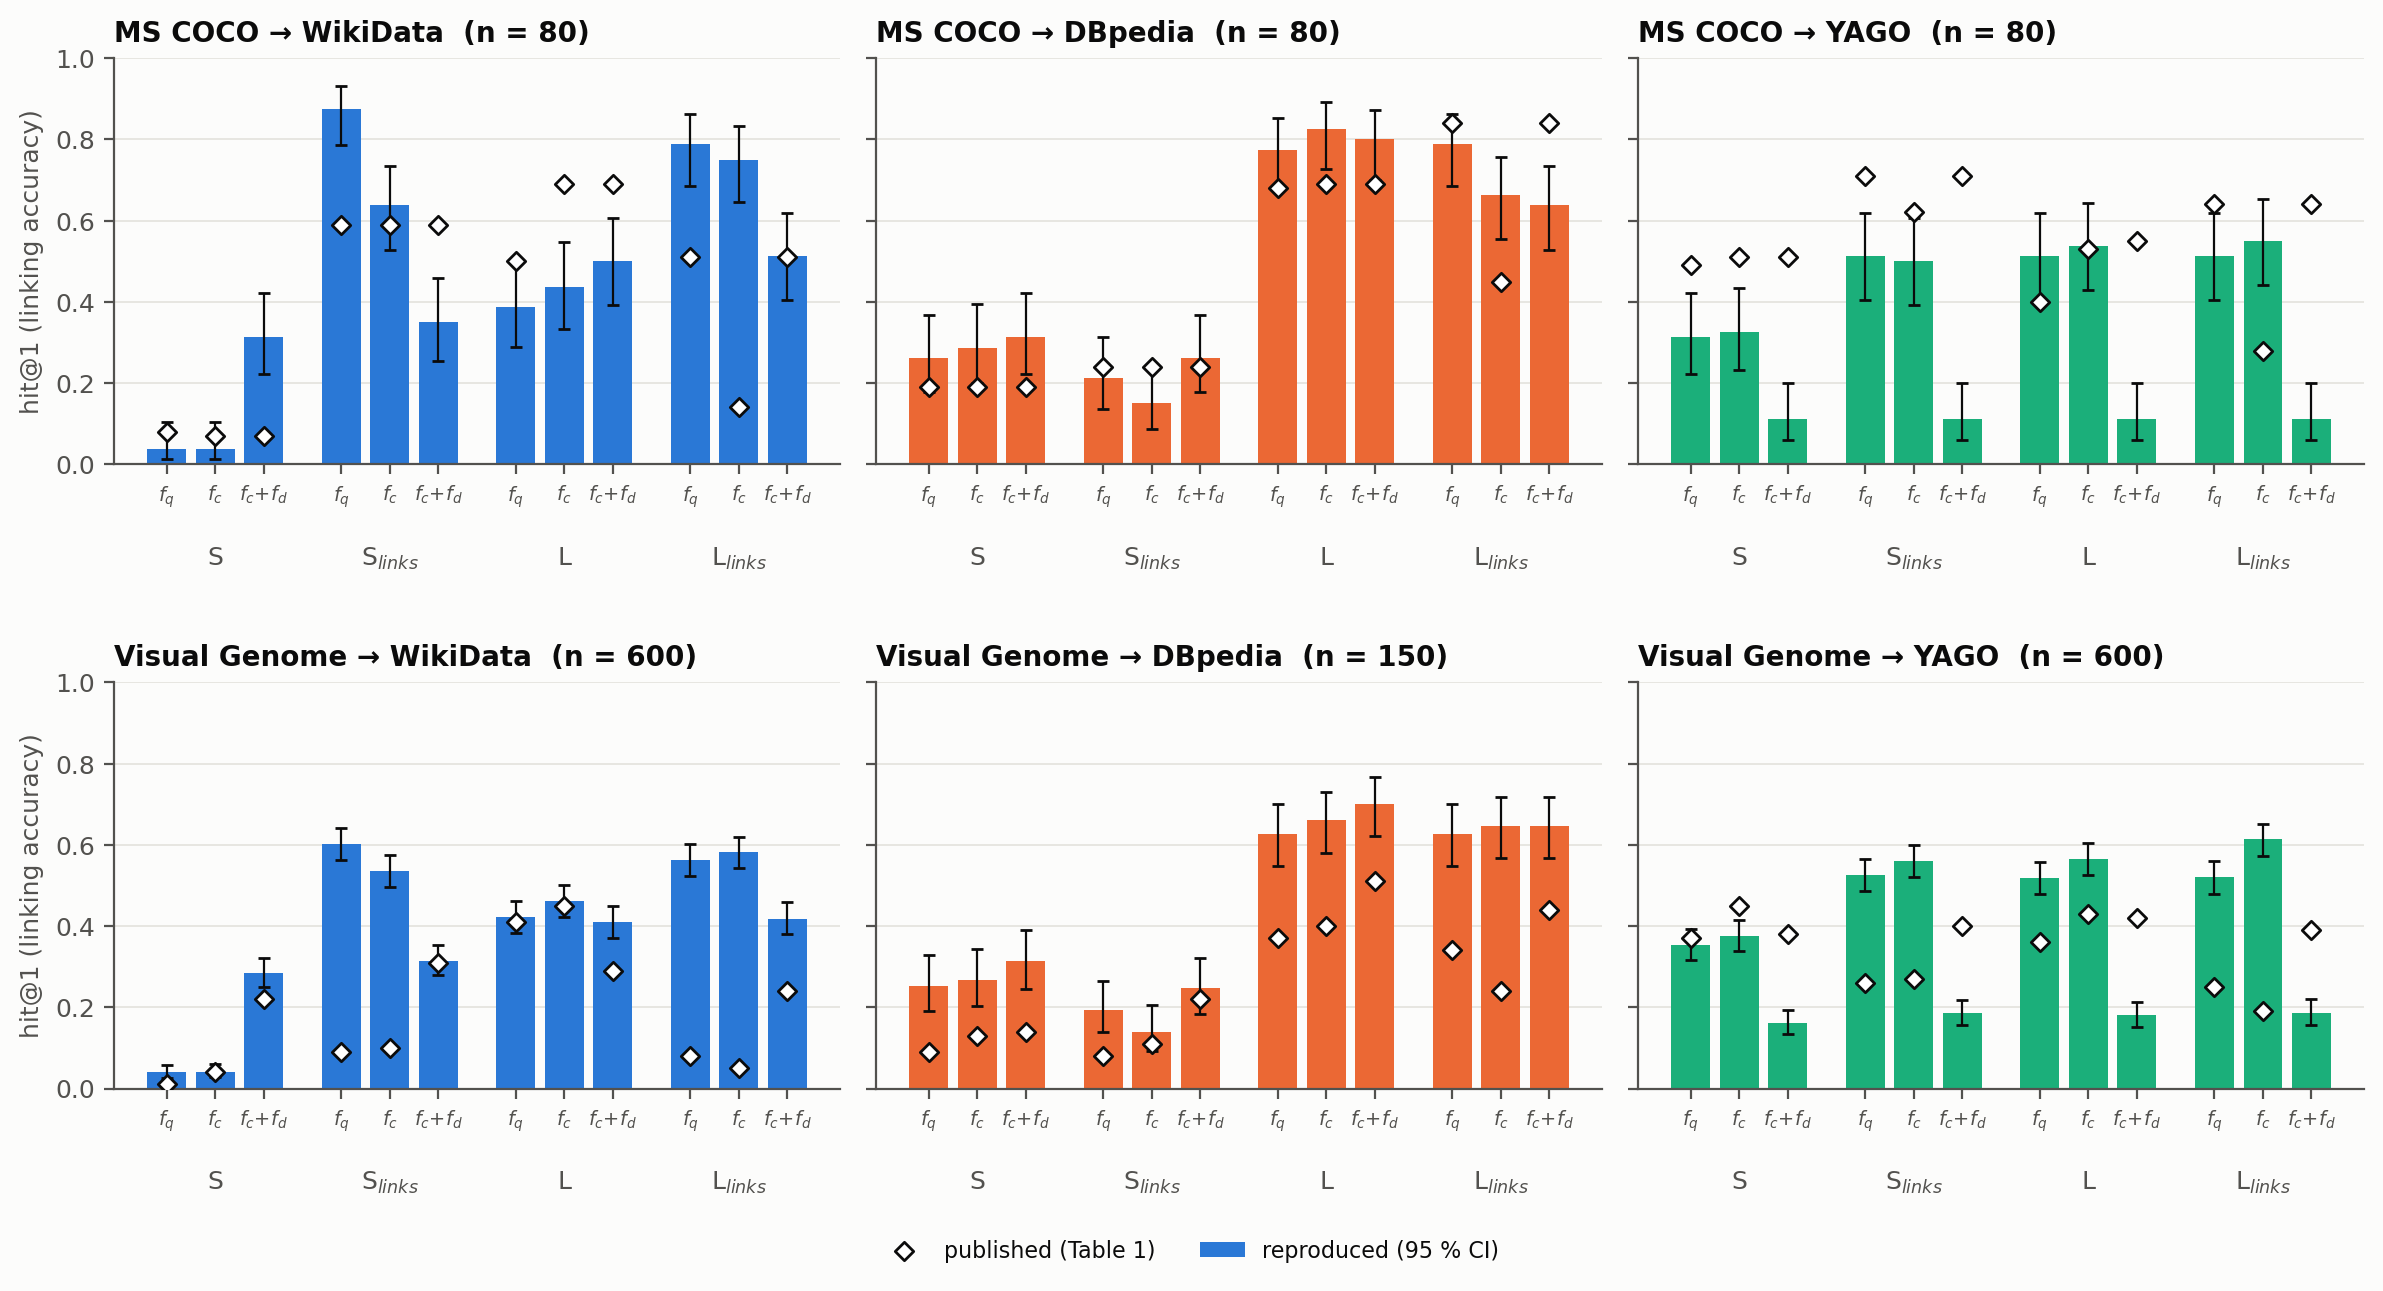

In [4]:
from IPython.display import Image
Image(filename=str(FIGURES / "reproduction" / "hit1_reproduced_vs_published.png"), width=1000)

*Bars: reproduced hit@1 with 95 % Wilson intervals. Diamonds: the published value for the same cell. A diamond inside the error bar means the two are statistically indistinguishable.*

## 6.3 How well do the numbers agree?

Cell-by-cell agreement is summarised by the mean absolute difference and by the Spearman rank correlation between published and reproduced values (do the *same conditions* come out best?):

coco/wikidata              mean |difference| = 0.14   Spearman rho = +0.71   (36 cells)
coco/dbpedia               mean |difference| = 0.10   Spearman rho = +0.89   (36 cells)
coco/yago                  mean |difference| = 0.24   Spearman rho = +0.12   (36 cells)
visual_genome/wikidata     mean |difference| = 0.17   Spearman rho = +0.56   (36 cells)
visual_genome/dbpedia      mean |difference| = 0.17   Spearman rho = +0.86   (36 cells)
visual_genome/yago         mean |difference| = 0.13   Spearman rho = +0.20   (36 cells)


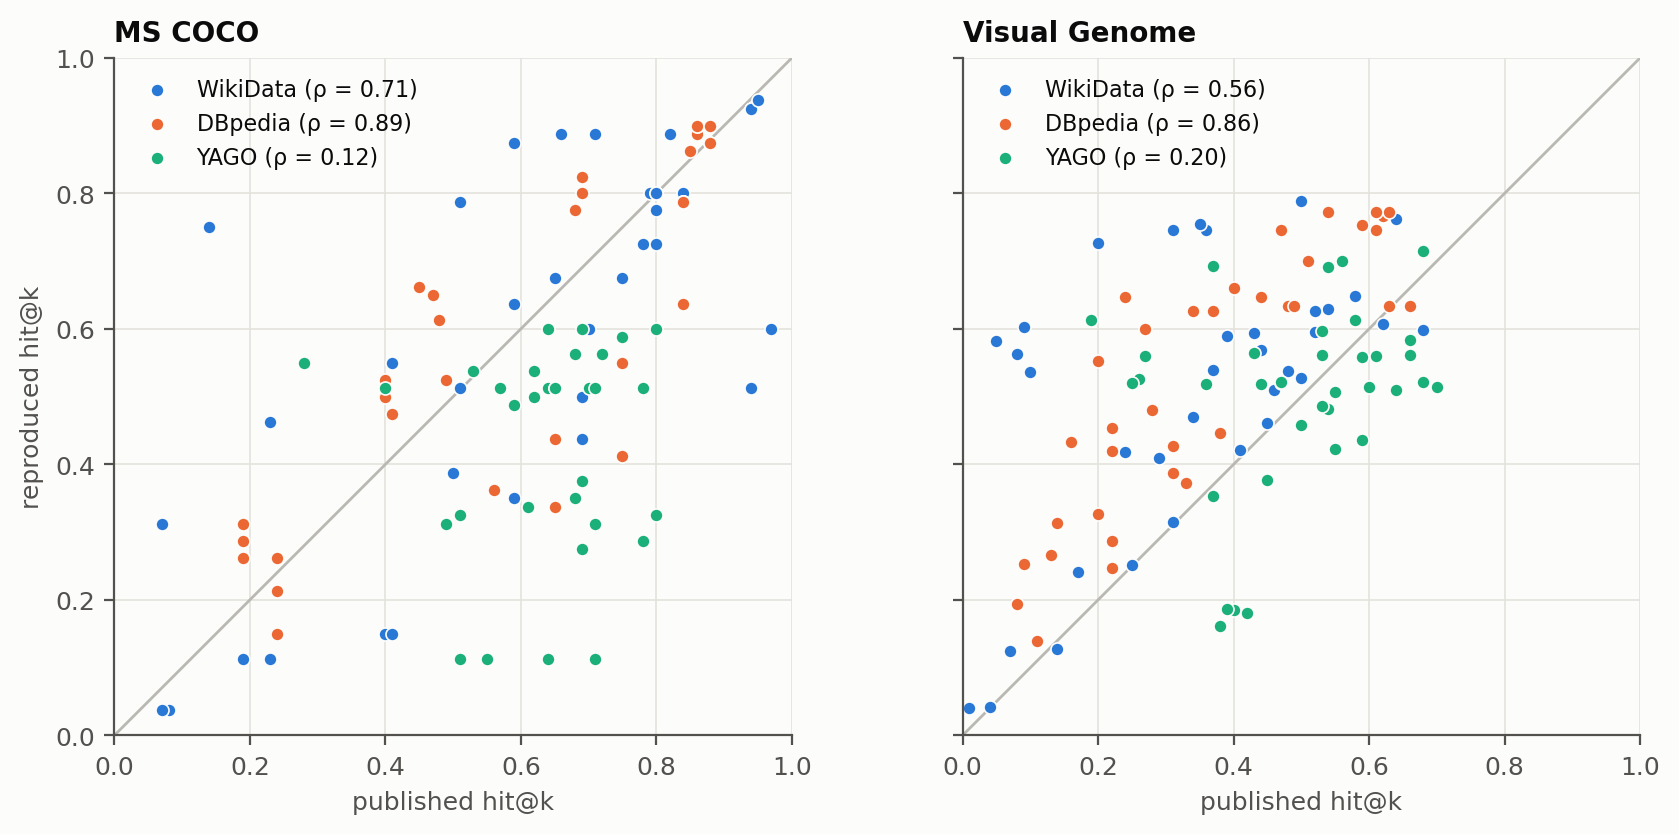

In [5]:
agreement = json.loads((RESULTS / "reproduction" / "agreement_with_paper.json").read_text())
for pair, stats in agreement.items():
    print(f"{pair:26s} mean |difference| = {stats['mean_abs_difference']:.2f}   Spearman rho = {stats['spearman_rho']:+.2f}   ({stats['cells']} cells)")
Image(filename=str(FIGURES / "reproduction" / "published_vs_reproduced_scatter.png"), width=800)

**Reading the comparison honestly.**

* The reproduction is **not** a digit-for-digit match, and was not expected to be: the graphs are two years older, YAGO changed major version, the COCO ground truth had to be rebuilt, and ten details of the method had to be inferred (Chapter 3.7).
* **What does reproduce** (qualitative behaviour):
  * `S` queries without ordering are close to useless on WikiData — the “any property” match returns lexemes, statements and aliases in arbitrary order.
  * Ordering by outgoing links is the single most effective ingredient on WikiData.
  * Candidate selection ($f_c$) raises hit@3 and hit@5 for the label queries (`L`, `L_links`) on every graph: it *finds* more correct entities.
  * With `_links` queries, $f_c$ alone can lower hit@1 (clearly so on COCO), because popular entities reached through synonyms overtake the right one — the effect the paper describes.
  * Disambiguation ($f_d$) is not a reliable improvement: it helps where the incoming order is arbitrary (the `S` query on WikiData) is neutral to mildly positive on DBpedia (as in the paper), and lowers hit@1 for the link-ordered queries on WikiData and for every query on YAGO. The paper's Visual Genome/WikiData/`L` column shows such a drop too (0.45 → 0.29).
* **What does not reproduce:**
  * On YAGO, disambiguation collapses hit@1. This is a property of YAGO 4.5, which did not exist when the paper was written (Chapter 7 explains the mechanism).
  * In the paper, `_links` queries on Visual Genome have very low hit@1 but high hit@5 for $f_q$ (e.g. WikiData 0.08 → 0.68); here the right entity is usually ranked first. We could not determine why; the paper's Section 5.3 speaks of “incoming links” although its queries are described as counting outgoing ones, so a different link count may have been used.
* **Two cells of the published table are internally inconsistent** (hit@k must not decrease with k): COCO/WikiData/`L`/$f_q$ (hit@3 = 0.70, hit@5 = 0.65) and COCO/DBpedia/`S_links`/$f_c$ (hit@1 = 0.24, hit@3 = 0.19). They cannot be reproduced by any implementation.

## 6.4 Where does the correct entity get lost? *(additional analysis)*

hit@1 mixes two different failures: the right entity was **never retrieved**, or it was retrieved and **ranked too low**. The stored results allow them to be separated:

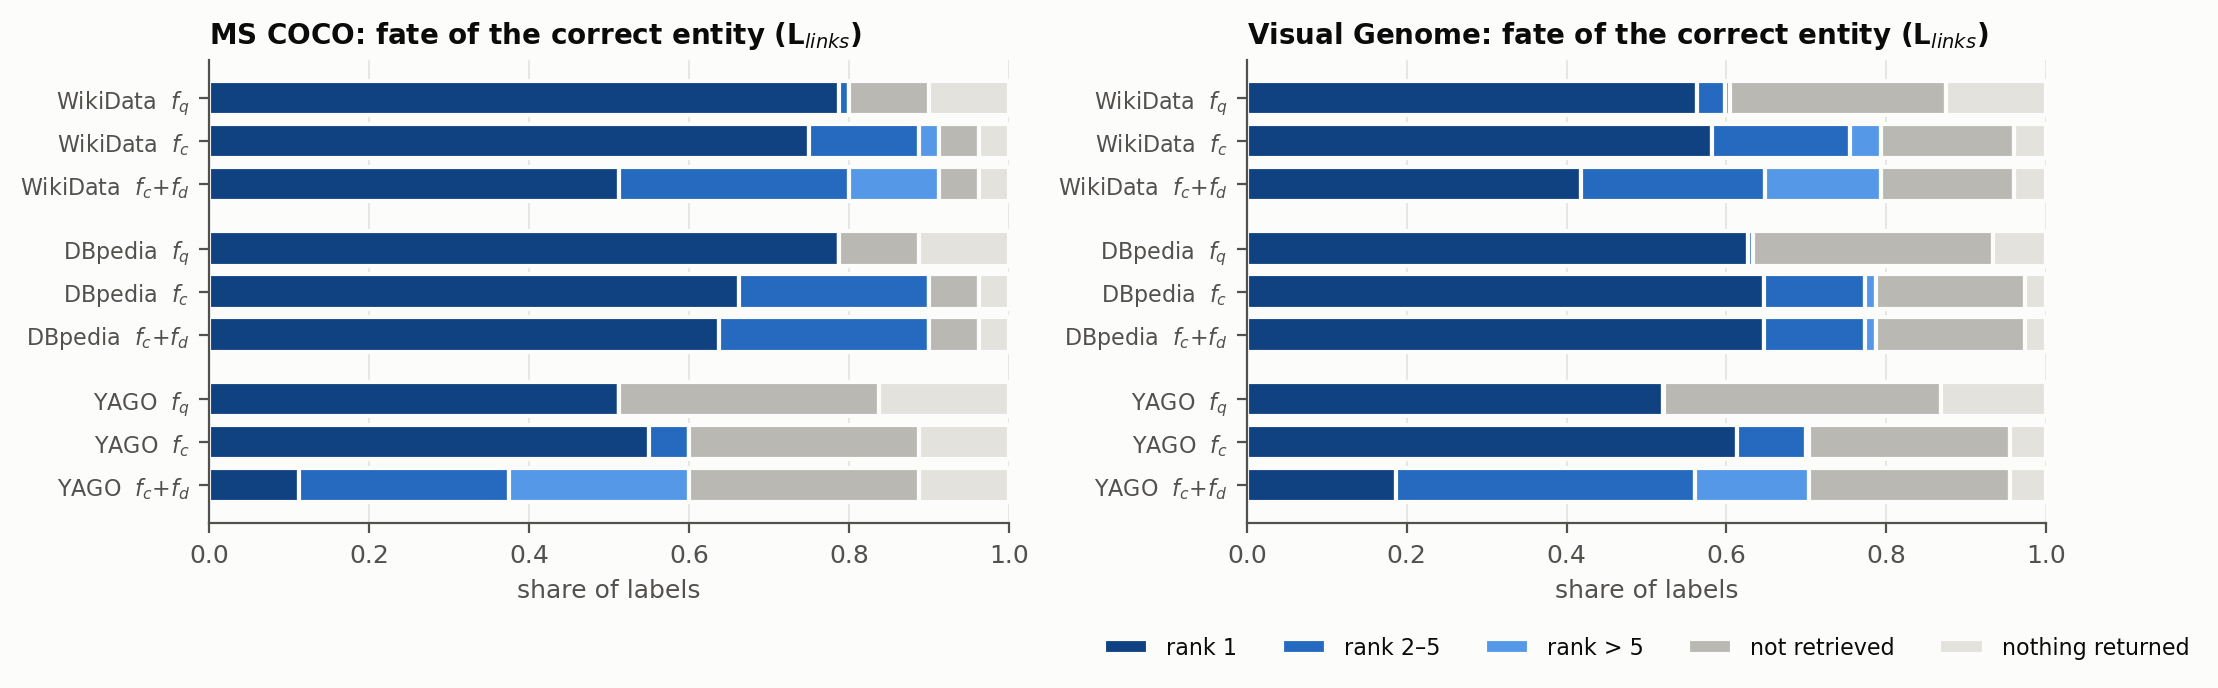

In [6]:
Image(filename=str(FIGURES / "reproduction" / "failure_decomposition.png"), width=1000)

In [7]:
decomposition = json.loads((RESULTS / "reproduction" / "failure_decomposition.json").read_text())
for key, shares in decomposition.items():
    if key.startswith("visual_genome"):
        lost = shares["not retrieved"] + shares["nothing returned"]
        print(f"{key:34s} ranked 1st {shares['rank 1']:.2f} | retrieved but lower {shares['rank 2–5'] + shares['rank > 5']:.2f} | never retrieved {lost:.2f}")

visual_genome/wikidata/fq          ranked 1st 0.56 | retrieved but lower 0.04 | never retrieved 0.40
visual_genome/wikidata/fc          ranked 1st 0.58 | retrieved but lower 0.21 | never retrieved 0.21
visual_genome/wikidata/fc+fd       ranked 1st 0.42 | retrieved but lower 0.38 | never retrieved 0.21
visual_genome/dbpedia/fq           ranked 1st 0.63 | retrieved but lower 0.01 | never retrieved 0.37
visual_genome/dbpedia/fc           ranked 1st 0.65 | retrieved but lower 0.14 | never retrieved 0.21
visual_genome/dbpedia/fc+fd        ranked 1st 0.65 | retrieved but lower 0.14 | never retrieved 0.21
visual_genome/yago/fq              ranked 1st 0.52 | retrieved but lower 0.00 | never retrieved 0.48
visual_genome/yago/fc              ranked 1st 0.61 | retrieved but lower 0.09 | never retrieved 0.30
visual_genome/yago/fc+fd           ranked 1st 0.19 | retrieved but lower 0.52 | never retrieved 0.30


Two lessons for the rest of the tutorial:

1. Under $f_c + f_d$ a large share of labels has the right entity *in the pool but not on top* — a pure **ranking** failure. That is what Chapters 7–9 attack.
2. For roughly a fifth to a third of the labels the right entity is **never retrieved**. No re-ranking can recover those; Chapter 7 looks at why.

## 6.5 External baselines

The paper compares with DBpedia Spotlight (0.525 on COCO) and AIDA (no hits). Neither could be re-run: the public Spotlight web service refused connections throughout this work, and the AIDA service behind the URL given in the paper returned HTTP 404 (November 2026). `experiments/run_spotlight_baseline.py` is ready for when Spotlight is reachable. The published values are therefore neither confirmed nor contradicted.

## 6.6 Limitations of this reproduction

* Live graphs: results describe November 2026, and the `S`/`L` result order is whatever the endpoints returned at that time.
* Ground truth for COCO was curated by this project, not by the authors.
* Visual Genome is evaluated on a sample; DBpedia on a smaller one.
* Recognition (YOLO) is not executed — the paper's evaluation involves no images either.

**Next:** Chapter 7 turns the anomalies seen here into understood weaknesses.